# NB14: Pre-op vs Post-op Comparison

> **Local pipeline required.** This notebook inspects longitudinal comparison outputs and cannot run in Google Colab. See NB00--NB06 and NB08 for Colab-compatible notebooks.

## Purpose
Visualize and quantify longitudinal changes between pre-operative and
post-operative multimodal MRI for each glioma patient. Interpret changes
in the context of mathematical challenges in brain mechanics.

## Interactive Comparison
```bash
bash scripts/freeview_preop_postop.sh --subject PAT16
```

## Context
Tumor resection changes the brain's mechanical state:
- Tissue removal creates a cavity with altered boundary conditions
- Peri-tumoral edema changes tissue compliance (increased MD)
- Fiber tract disruption alters anisotropic stiffness (decreased FA)
- Ventricle enlargement modifies CSF dynamics
- Brain shift post-surgery changes the reference geometry

In [3]:
import sys
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

DERIV_ROOT = REPO_ROOT / 'derivatives'
REG_DIR = DERIV_ROOT / 'registered_t1w'
BIDS_ROOT = REPO_ROOT / 'data' / 'BIDS_preop_postop'
SUBJECTS = ['PAT16', 'PAT25']

plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

## 1. Comparison Report Summary

Load the JSON report from `compare_preop_postop.py`.

In [5]:
for sub in SUBJECTS:
    report_path = REG_DIR / f'sub-{sub}' / 'preop_vs_postop' / 'comparison_report.json'
    print(f'\n{"=" * 60}')
    print(f' sub-{sub}: Pre-op vs Post-op')
    print(f'{"=" * 60}')

    if not report_path.exists():
        print('  Report not yet generated. Run:')
        print(f'    python scripts/compare_preop_postop.py --subject {sub}')
        continue

    with open(report_path) as f:
        report = json.load(f)

    analyses = report.get('analyses', {})

    for metric in ['delta_fa', 'delta_md', 'delta_ad', 'delta_rd']:
        if metric in analyses:
            d = analyses[metric]
            print(f'  {metric}: mean={d["mean"]:.6f}, std={d["std"]:.6f}, '
                  f'range=[{d["min"]:.6f}, {d["max"]:.6f}]')

    if 'delta_fc' in analyses:
        fc = analyses['delta_fc']
        print(f'  FC: {fc["n_connections_weakened"]} weakened, '
              f'{fc["n_connections_strengthened"]} strengthened')

    if 'mechanics_notes' in analyses:
        print('\n  Brain mechanics implications:')
        for note in analyses['mechanics_notes']:
            print(f'    - {note}')


 sub-PAT16: Pre-op vs Post-op
  Report not yet generated. Run:
    python scripts/compare_preop_postop.py --subject PAT16

 sub-PAT25: Pre-op vs Post-op
  Report not yet generated. Run:
    python scripts/compare_preop_postop.py --subject PAT25


## 2. Delta-FA and Delta-MD Maps

Voxel-wise difference maps (post-op minus pre-op) reveal regions where
tissue microstructure changed due to surgery.

In [6]:
try:
    import nibabel as nib

    for sub in SUBJECTS:
        comp_dir = REG_DIR / f'sub-{sub}' / 'preop_vs_postop'
        delta_fa_path = comp_dir / 'delta_fa_space-T1w.nii.gz'
        delta_md_path = comp_dir / 'delta_md_space-T1w.nii.gz'

        if not delta_fa_path.exists():
            print(f'sub-{sub}: delta maps not available')
            continue

        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        fig.suptitle(f'sub-{sub}: Post-op minus Pre-op', fontsize=14)

        fa = np.asarray(nib.load(str(delta_fa_path)).dataobj)
        slices = [fa.shape[2] // 3, fa.shape[2] // 2, 2 * fa.shape[2] // 3]

        for j, sl_idx in enumerate(slices):
            im = axes[0][j].imshow(np.rot90(fa[:, :, sl_idx]),
                                   cmap='RdBu_r', vmin=-0.3, vmax=0.3)
            axes[0][j].set_title(f'delta-FA (z={sl_idx})')
            axes[0][j].axis('off')
            plt.colorbar(im, ax=axes[0][j], fraction=0.046)

        if delta_md_path.exists():
            md = np.asarray(nib.load(str(delta_md_path)).dataobj)
            for j, sl_idx in enumerate(slices):
                im = axes[1][j].imshow(np.rot90(md[:, :, sl_idx]),
                                       cmap='RdBu_r', vmin=-5e-4, vmax=5e-4)
                axes[1][j].set_title(f'delta-MD (z={sl_idx})')
                axes[1][j].axis('off')
                plt.colorbar(im, ax=axes[1][j], fraction=0.046)

        plt.tight_layout()
        plt.show()

except Exception as e:
    print(f'Delta map visualization not available: {e}')

sub-PAT16: delta maps not available
sub-PAT25: delta maps not available


## 3. ROI Volume Changes

Bar chart of the largest volume changes between pre-op and post-op.

In [7]:
for sub in SUBJECTS:
    report_path = REG_DIR / f'sub-{sub}' / 'preop_vs_postop' / 'comparison_report.json'
    if not report_path.exists():
        continue

    with open(report_path) as f:
        report = json.load(f)

    vol_changes = report.get('analyses', {}).get('volume_changes', {})
    if not vol_changes:
        print(f'sub-{sub}: no volume change data')
        continue

    # Sort by absolute delta and take top 15
    sorted_changes = sorted(vol_changes.values(),
                            key=lambda x: abs(x['delta_mm3']),
                            reverse=True)[:15]

    names = [c['name'] for c in sorted_changes]
    deltas = [c['delta_mm3'] / 1000 for c in sorted_changes]  # convert to cm3
    colors = ['red' if d < 0 else 'steelblue' for d in deltas]

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(range(len(names)), deltas, color=colors)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontsize=9)
    ax.set_xlabel('Volume change (cm^3)')
    ax.set_title(f'sub-{sub}: Top ROI volume changes (post-op minus pre-op)')
    ax.axvline(0, color='black', linewidth=0.5)
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

## 4. T1w Side-by-Side Comparison

Direct visual comparison of pre-op and post-op T1w anatomy.
For interactive side-by-side viewing:
```bash
bash scripts/freeview_preop_postop.sh --subject PAT16
```

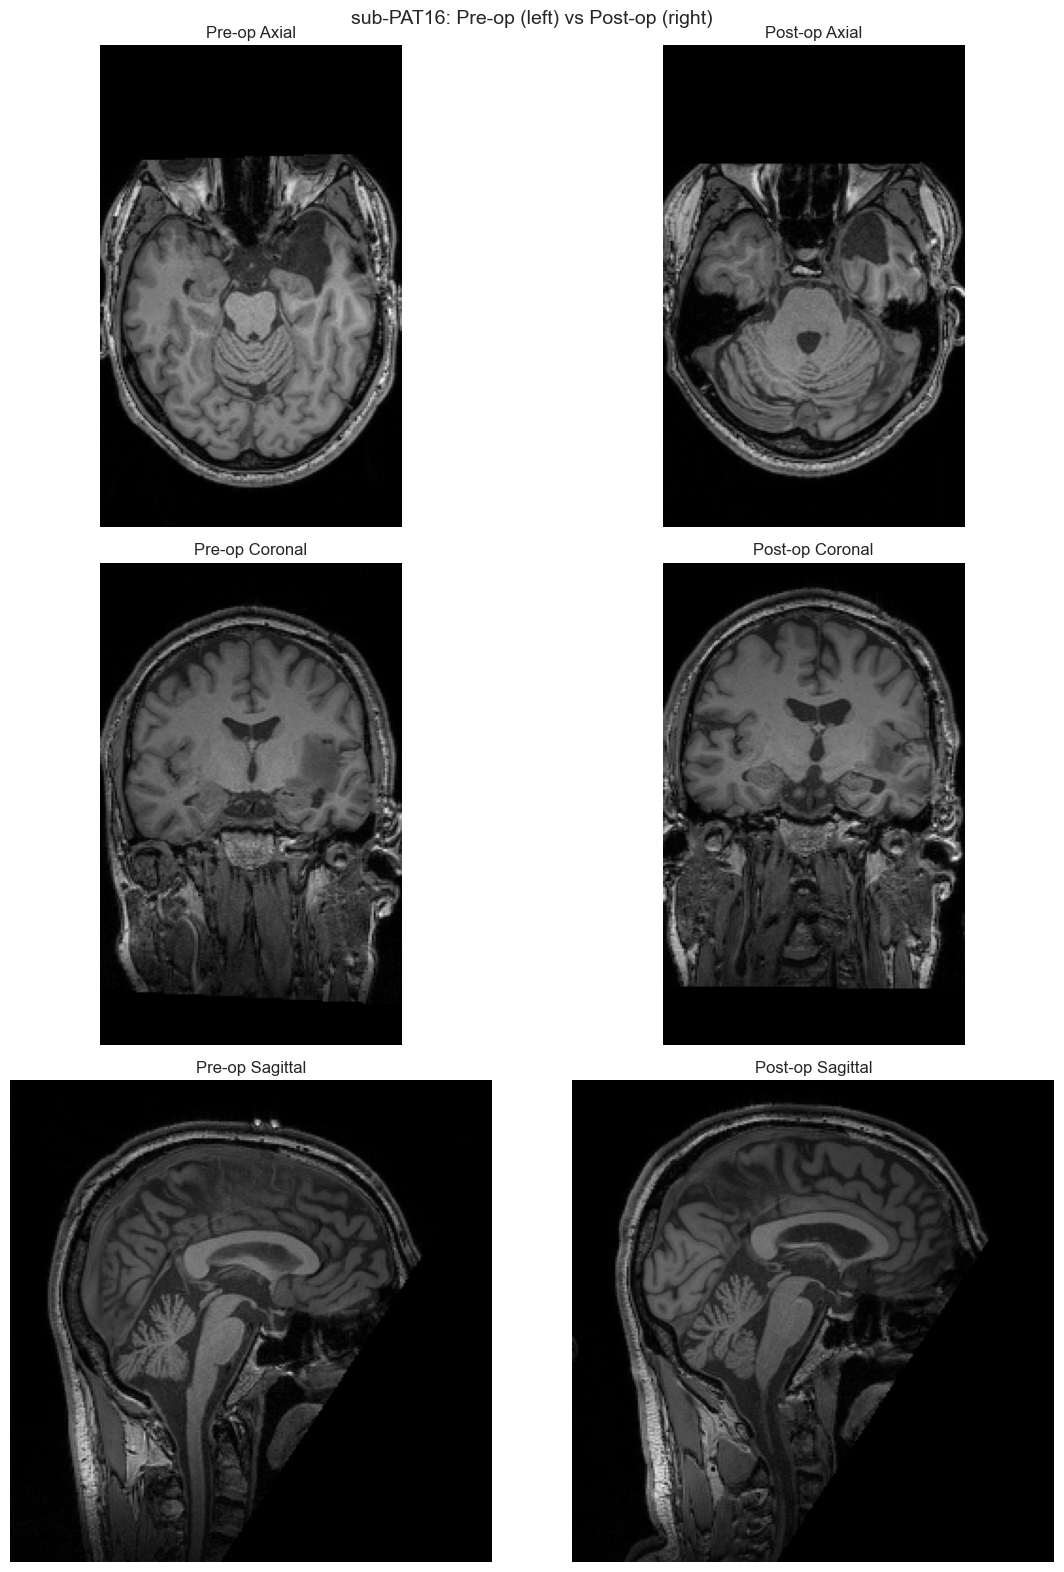

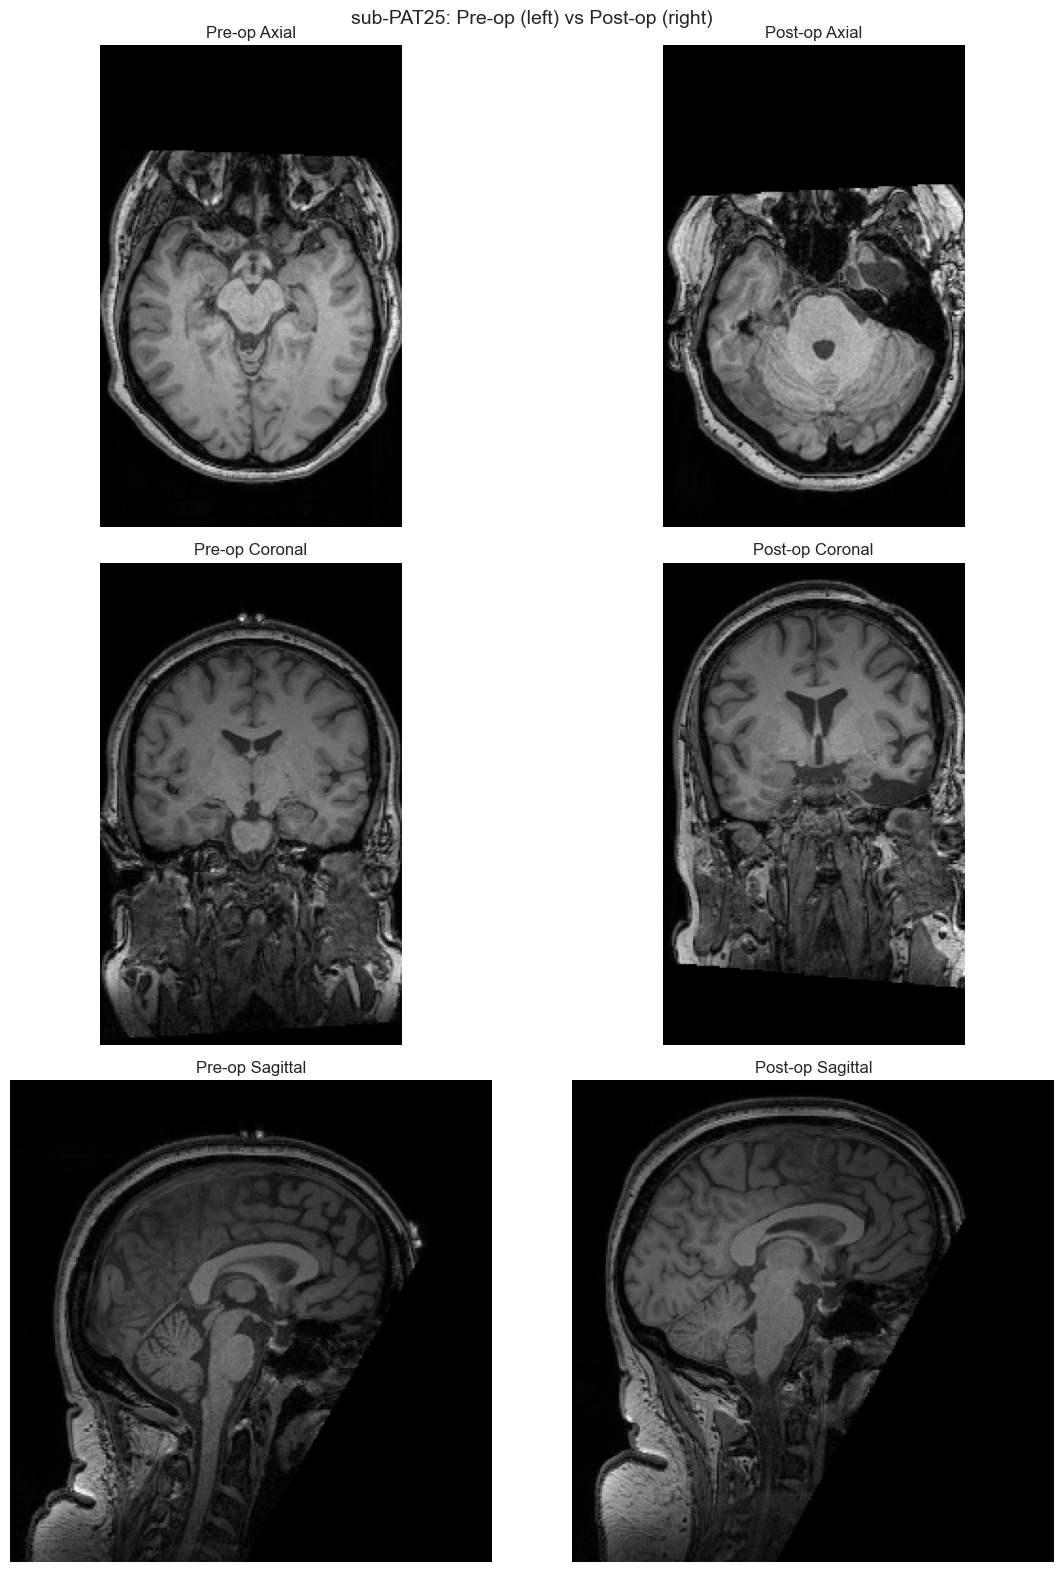

In [9]:
try:
    import nibabel as nib

    for sub in SUBJECTS:
        pre_t1w = BIDS_ROOT / f'sub-{sub}' / 'ses-preop' / 'anat' / f'sub-{sub}_ses-preop_T1w.nii.gz'
        post_t1w = BIDS_ROOT / f'sub-{sub}' / 'ses-postop' / 'anat' / f'sub-{sub}_ses-postop_T1w.nii.gz'

        if not (pre_t1w.exists() and post_t1w.exists()):
            print(f'sub-{sub}: T1w not available for both sessions')
            continue

        pre = np.asarray(nib.load(str(pre_t1w)).dataobj)
        post = np.asarray(nib.load(str(post_t1w)).dataobj)

        fig, axes = plt.subplots(3, 2, figsize=(12, 16))
        fig.suptitle(f'sub-{sub}: Pre-op (left) vs Post-op (right)', fontsize=14)

        # Three orthogonal views
        views = [
            ('Axial', lambda d, s: np.rot90(d[:, :, s]), pre.shape[2] // 2),
            ('Coronal', lambda d, s: np.rot90(d[:, s, :]), pre.shape[1] // 2),
            ('Sagittal', lambda d, s: np.rot90(d[s, :, :]), pre.shape[0] // 2),
        ]

        for i, (view_name, slicer, mid) in enumerate(views):
            axes[i][0].imshow(slicer(pre, mid), cmap='gray')
            axes[i][0].set_title(f'Pre-op {view_name}')
            axes[i][0].axis('off')

            if post.shape == pre.shape:
                axes[i][1].imshow(slicer(post, mid), cmap='gray')
            else:
                post_mid = post.shape[[2, 1, 0][i]] // 2
                axes[i][1].imshow(slicer(post, post_mid), cmap='gray')
            axes[i][1].set_title(f'Post-op {view_name}')
            axes[i][1].axis('off')

        plt.tight_layout()
        plt.show()

except Exception as e:
    print(f'Side-by-side comparison not available: {e}')

## 5. Deformation Field Analysis (Step 5b)

The longitudinal ANTs SyN registration (`register_longitudinal.sh`) produces
dense deformation fields that encode **empirical tissue motion** between the
pre-operative and post-operative brain states.  These fields are the primary
validation data for finite element models of brain mechanics.

#### Key outputs

| File | Description | Units / interpretation |
|------|-------------|----------------------|
| `displacement_magnitude.nii.gz` | ‖**u**(**x**)‖ at each voxel | mm; expected 1–5 mm far from cavity, 10–15 mm near cavity |
| `jacobian_preop_to_postop.nii.gz` | det(∇φ) — local volume change | J > 1 = expansion (e.g. ventricles); J < 1 = contraction |
| `cavity_mask_postop.nii.gz` | Resection cavity mask (from tumor prior) | Binary; used to exclude cavity from SyN cost function |
| `T1w_preop_in_postop.nii.gz` | Pre-op T1w warped to post-op space | Enables direct voxel-wise comparison |
| `preop_to_postop_1Warp.nii.gz` | Full 3D displacement vector field | 5D array (x, y, z, 1, 3) |

#### Cavity masking

The cavity mask is derived from the **pre-operative tumor mask** (thresholded
at p > 0.5 and dilated ~3 mm for surgical margins), providing reliable spatial
correspondence with the actual resection site.

#### Interactive inspection
```bash
bash scripts/freeview_deformation.sh --subject PAT16
```


  sub-PAT16: Deformation Field Analysis
  Cavity centroid: voxel (105, 147, 118)


/var/folders/1g/_4x26lps6mgg1tr73d7g2bmh0000gp/T/ipykernel_7830/1779445816.py:75: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


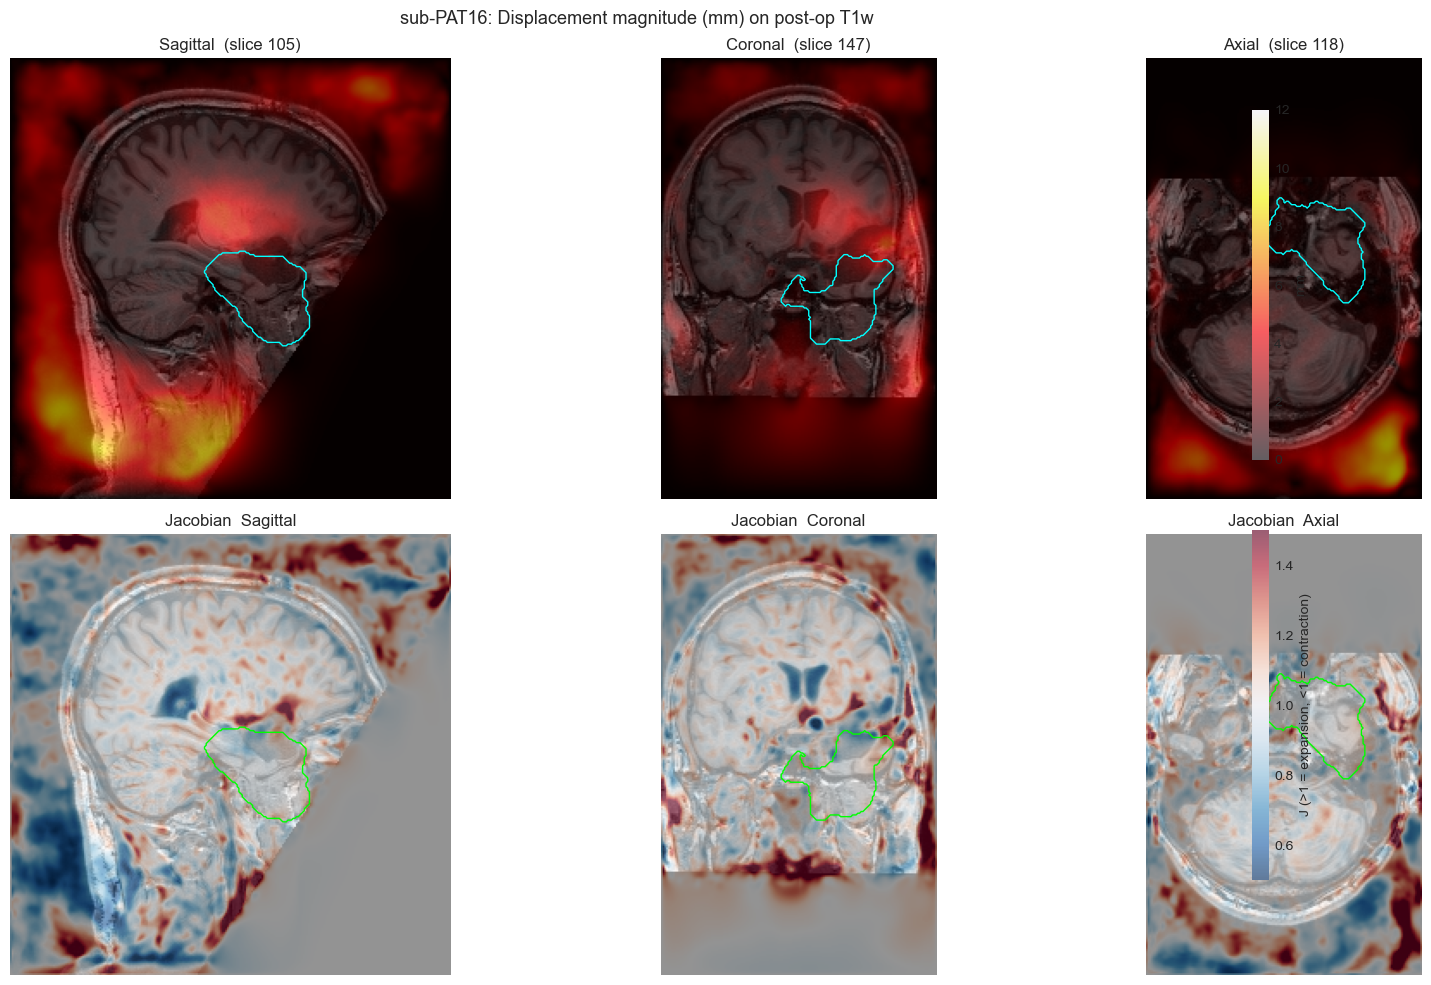

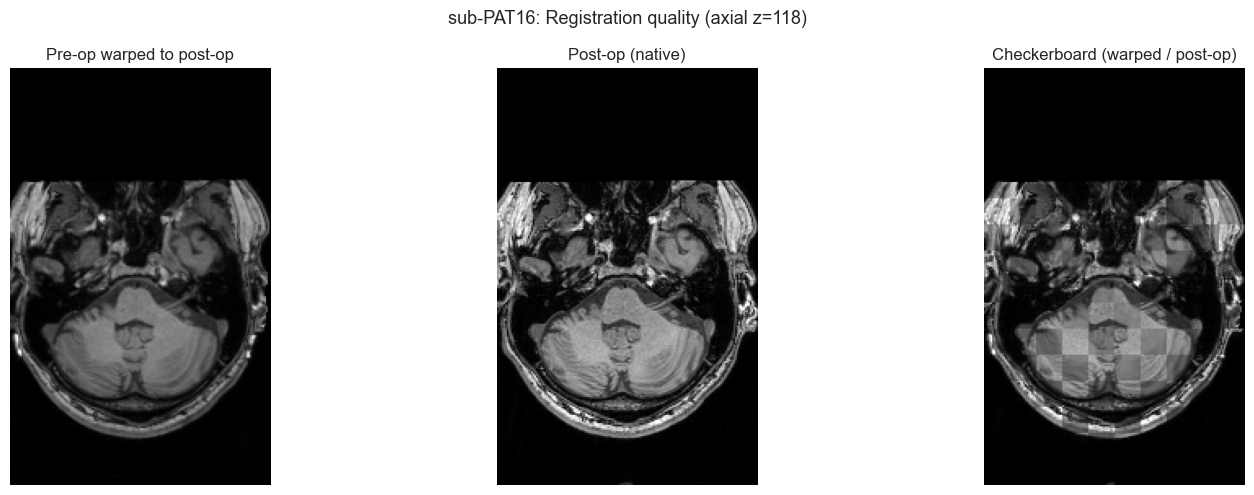

  Displacement: mean=1.75 mm, median=0.99 mm, max=12.63 mm, 95th pctl=5.85 mm
  Jacobian:  mean=0.9998, expanding (J>1.05)=27.3%, contracting (J<0.95)=32.4%
  Cavity: 71582 voxels, ~71.6 cm³

  sub-PAT25: Deformation Field Analysis
  Cavity centroid: voxel (108, 138, 119)


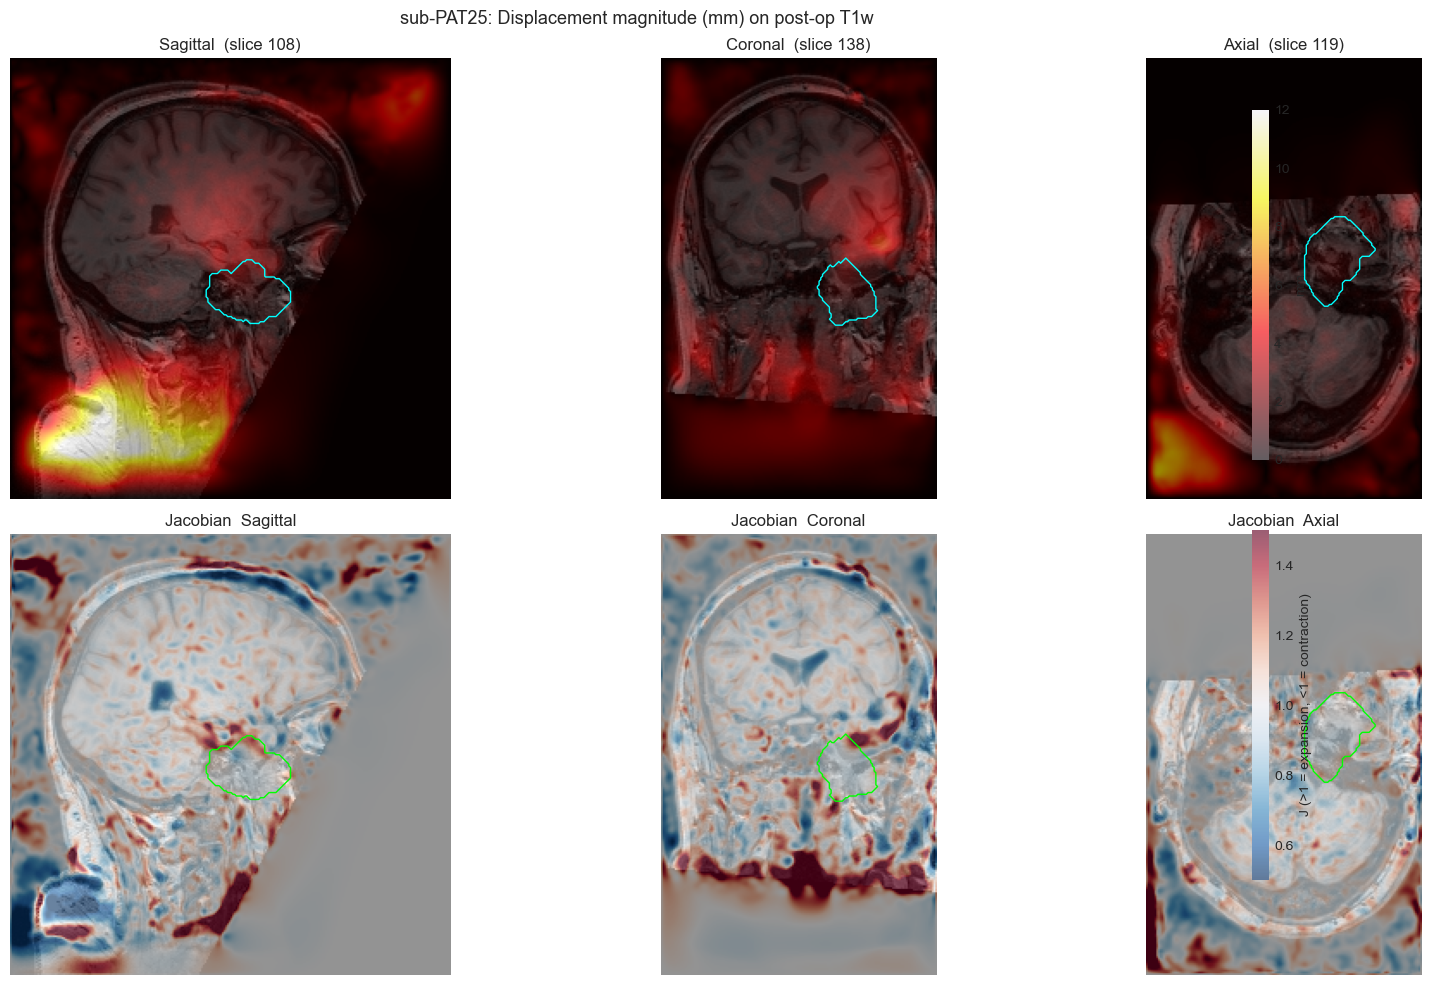

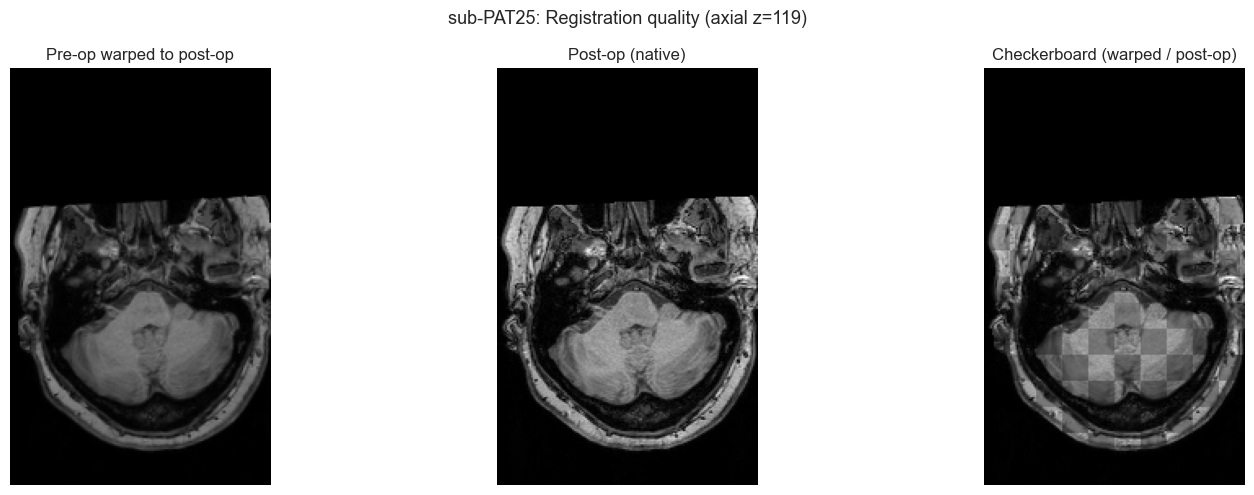

  Displacement: mean=2.08 mm, median=0.98 mm, max=16.61 mm, 95th pctl=8.47 mm
  Jacobian:  mean=0.9999, expanding (J>1.05)=27.8%, contracting (J<0.95)=32.1%
  Cavity: 28181 voxels, ~28.2 cm³


In [11]:
import nibabel as nib
from matplotlib.colors import ListedColormap

cavity_cmap = ListedColormap([[1, 1, 0, a] for a in np.linspace(0, 0.5, 256)])

for sub in SUBJECTS:
    long_dir = REG_DIR / f'sub-{sub}' / 'longitudinal'
    disp_path = long_dir / 'displacement_magnitude.nii.gz'
    jac_path  = long_dir / 'jacobian_preop_to_postop.nii.gz'
    cavity_path = long_dir / 'cavity_mask_postop.nii.gz'
    postop_path = BIDS_ROOT / f'sub-{sub}' / 'ses-postop' / 'anat' / f'sub-{sub}_ses-postop_T1w.nii.gz'
    warped_path = long_dir / 'T1w_preop_in_postop.nii.gz'

    if not disp_path.exists():
        print(f'sub-{sub}: longitudinal registration not yet run')
        print(f'  Run: bash scripts/register_longitudinal.sh --subject {sub}')
        continue

    disp_img = nib.as_closest_canonical(nib.load(str(disp_path)))
    disp = disp_img.get_fdata()
    jac = nib.as_closest_canonical(nib.load(str(jac_path))).get_fdata() if jac_path.exists() else None
    cavity = nib.as_closest_canonical(nib.load(str(cavity_path))).get_fdata() if cavity_path.exists() else None
    t1_post = nib.as_closest_canonical(nib.load(str(postop_path))).get_fdata() if postop_path.exists() else None
    t1_warped = nib.as_closest_canonical(nib.load(str(warped_path))).get_fdata() if warped_path.exists() else None

    nz = t1_post[t1_post > 0] if t1_post is not None else np.array([0, 1])
    vmin_t1, vmax_t1 = np.percentile(nz, [1, 99.5])

    # Find cavity centroid for slice selection
    if cavity is not None and cavity.sum() > 0:
        coords = np.argwhere(cavity > 0.5)
        cx, cy, cz = coords.mean(axis=0).astype(int)
    else:
        cx, cy, cz = [s // 2 for s in disp.shape[:3]]

    print(f'\n{"=" * 70}')
    print(f'  sub-{sub}: Deformation Field Analysis')
    print(f'  Cavity centroid: voxel ({cx}, {cy}, {cz})')
    print(f'{"=" * 70}')

    # ── Figure 1: Displacement magnitude on T1w with cavity outline ──
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    fig.suptitle(f'sub-{sub}: Displacement magnitude (mm) on post-op T1w', fontsize=13, y=0.98)

    slices_info = [
        ('Sagittal', cx, lambda d, i=cx: np.rot90(d[i, :, :])),
        ('Coronal',  cy, lambda d, i=cy: np.rot90(d[:, i, :])),
        ('Axial',    cz, lambda d, i=cz: np.rot90(d[:, :, i])),
    ]

    for col, (name, idx, slicer) in enumerate(slices_info):
        if t1_post is not None:
            axes[0, col].imshow(slicer(t1_post), cmap='gray', vmin=vmin_t1, vmax=vmax_t1)
        im = axes[0, col].imshow(slicer(disp), cmap='hot', alpha=0.6, vmin=0, vmax=12)
        if cavity is not None:
            axes[0, col].contour(slicer(cavity), levels=[0.5], colors='cyan', linewidths=1)
        axes[0, col].set_title(f'{name}  (slice {idx})')
        axes[0, col].axis('off')

    plt.colorbar(im, ax=axes[0, :].tolist(), fraction=0.02, pad=0.02, label='mm')

    # ── Row 2: Jacobian on T1w ──
    if jac is not None:
        for col, (name, idx, slicer) in enumerate(slices_info):
            if t1_post is not None:
                axes[1, col].imshow(slicer(t1_post), cmap='gray', vmin=vmin_t1, vmax=vmax_t1)
            im2 = axes[1, col].imshow(slicer(jac), cmap='RdBu_r', alpha=0.6, vmin=0.5, vmax=1.5)
            if cavity is not None:
                axes[1, col].contour(slicer(cavity), levels=[0.5], colors='lime', linewidths=1)
            axes[1, col].set_title(f'Jacobian  {name}')
            axes[1, col].axis('off')
        plt.colorbar(im2, ax=axes[1, :].tolist(), fraction=0.02, pad=0.02,
                     label='J (>1 = expansion, <1 = contraction)')

    plt.tight_layout()
    plt.show()
    plt.close(fig)

    # ── Figure 2: Pre-op warped vs Post-op (registration quality) ──
    if t1_warped is not None and t1_post is not None:
        fig2, axes2 = plt.subplots(1, 3, figsize=(16, 5))
        fig2.suptitle(f'sub-{sub}: Registration quality (axial z={cz})', fontsize=13)

        ax_slice_post = np.rot90(t1_post[:, :, cz])
        ax_slice_warp = np.rot90(t1_warped[:, :, cz])

        axes2[0].imshow(ax_slice_warp, cmap='gray', vmin=vmin_t1, vmax=vmax_t1)
        axes2[0].set_title('Pre-op warped to post-op')
        axes2[0].axis('off')

        axes2[1].imshow(ax_slice_post, cmap='gray', vmin=vmin_t1, vmax=vmax_t1)
        axes2[1].set_title('Post-op (native)')
        axes2[1].axis('off')

        # Checkerboard
        block = 16
        rows, cols = ax_slice_post.shape
        checker = np.zeros_like(ax_slice_post)
        for r in range(0, rows, block):
            for c in range(0, cols, block):
                if ((r // block) + (c // block)) % 2 == 0:
                    checker[r:r+block, c:c+block] = ax_slice_warp[r:r+block, c:c+block]
                else:
                    checker[r:r+block, c:c+block] = ax_slice_post[r:r+block, c:c+block]
        axes2[2].imshow(checker, cmap='gray', vmin=vmin_t1, vmax=vmax_t1)
        axes2[2].set_title('Checkerboard (warped / post-op)')
        axes2[2].axis('off')

        plt.tight_layout()
        plt.show()
        plt.close(fig2)

    # ── Statistics ──
    brain_mask = disp > 0.1
    if brain_mask.sum() > 0:
        vals = disp[brain_mask]
        print(f'  Displacement: mean={np.mean(vals):.2f} mm, '
              f'median={np.median(vals):.2f} mm, '
              f'max={np.max(vals):.2f} mm, '
              f'95th pctl={np.percentile(vals, 95):.2f} mm')

    if jac is not None:
        jac_brain = jac[brain_mask & np.isfinite(jac) & (jac > 0)]
        n_expand = np.sum(jac_brain > 1.05)
        n_contract = np.sum(jac_brain < 0.95)
        print(f'  Jacobian:  mean={np.mean(jac_brain):.4f}, '
              f'expanding (J>1.05)={100 * n_expand / len(jac_brain):.1f}%, '
              f'contracting (J<0.95)={100 * n_contract / len(jac_brain):.1f}%')

    if cavity is not None:
        vox_vol = float(np.abs(np.linalg.det(disp_img.affine[:3, :3])))
        print(f'  Cavity: {int(cavity.sum())} voxels, '
              f'~{cavity.sum() * vox_vol / 1000:.1f} cm³')

### 5b. Displacement vs distance from cavity

The displacement magnitude should decay with distance from the resection
cavity — tissue closest to the surgical void undergoes the largest brain shift,
while distant regions are relatively unaffected.  This radial profile is
a key validation target for finite element models.

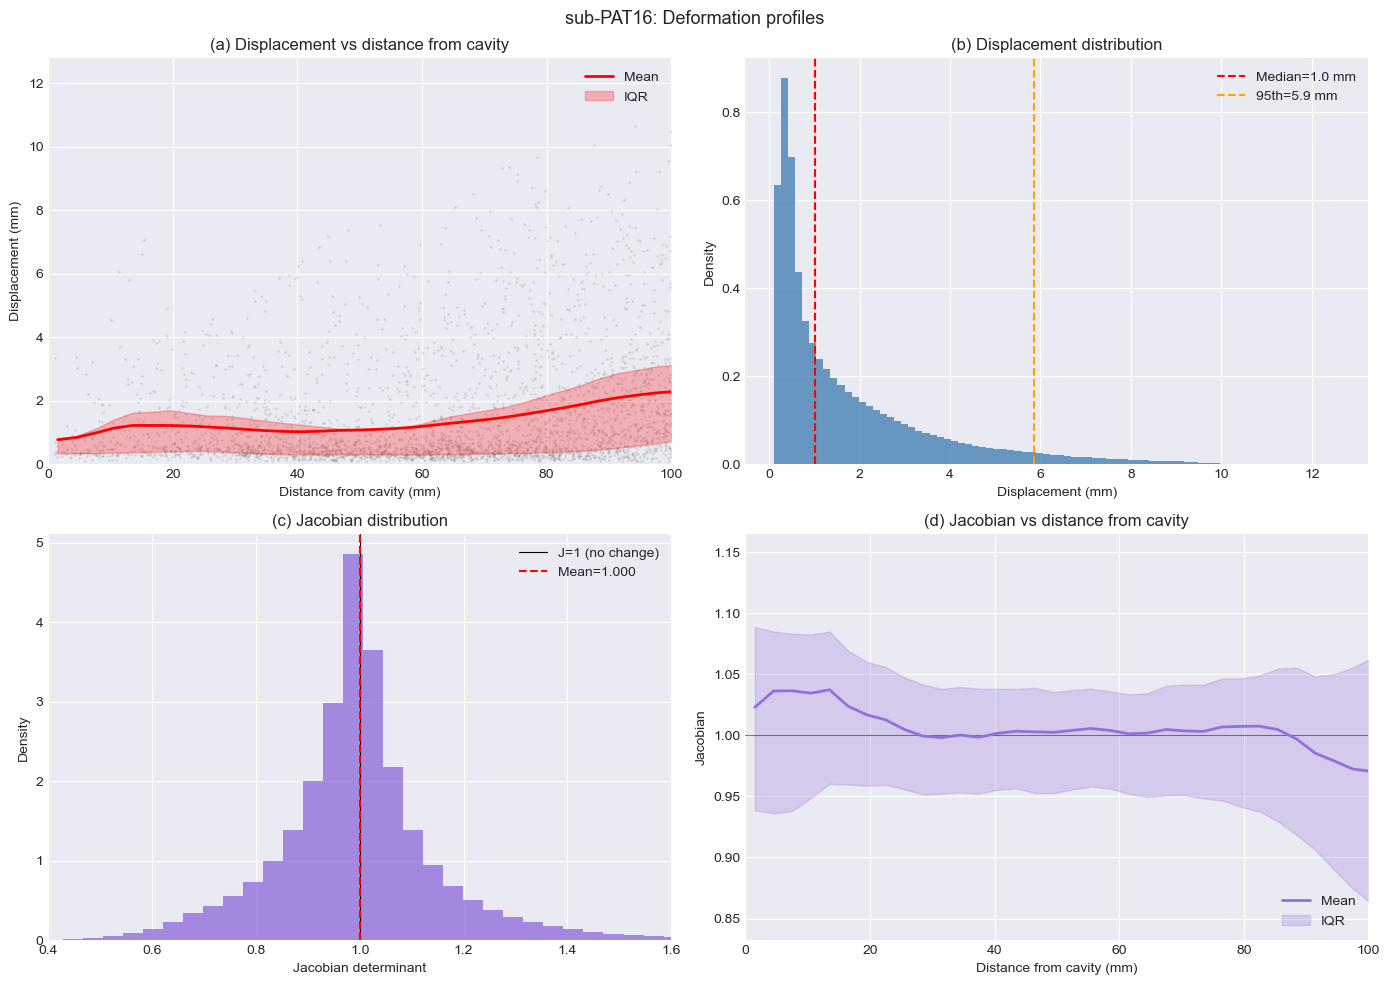

  Peri-cavity (<15 mm): disp mean=1.03 mm, median=0.55 mm, 95th=3.66 mm  |  J mean=1.0345
  Distant (>40 mm): disp mean=1.87 mm, median=1.12 mm, 95th=6.15 mm  |  J mean=0.9978



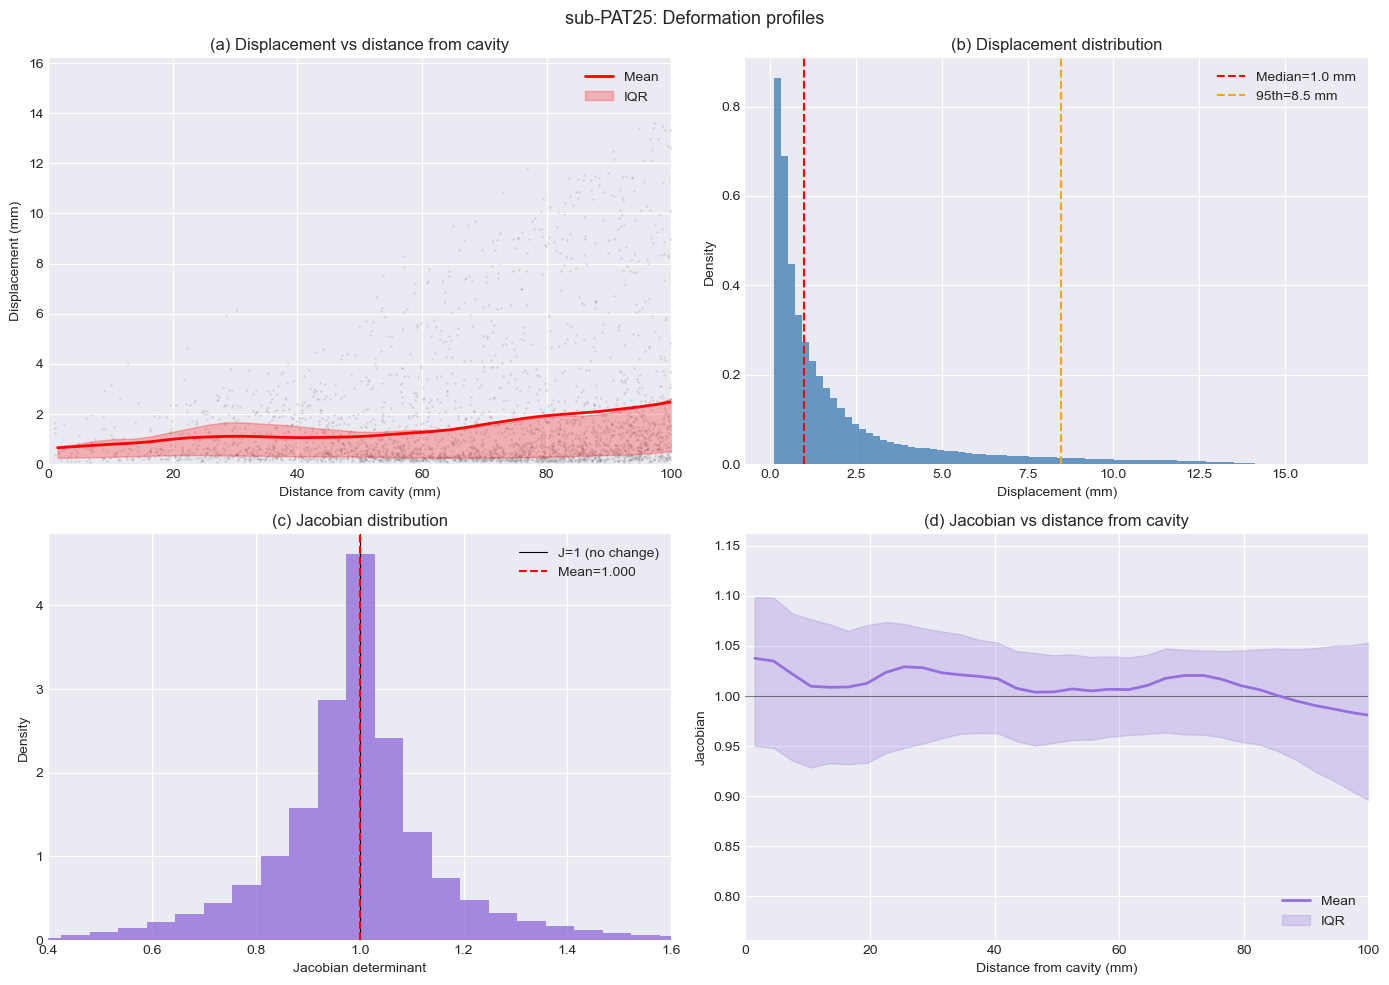

  Peri-cavity (<15 mm): disp mean=0.77 mm, median=0.48 mm, 95th=2.55 mm  |  J mean=1.0190
  Distant (>40 mm): disp mean=2.21 mm, median=1.06 mm, 95th=8.86 mm  |  J mean=0.9975



In [12]:
from scipy import ndimage as ndi

for sub in SUBJECTS:
    long_dir = REG_DIR / f'sub-{sub}' / 'longitudinal'
    disp_path = long_dir / 'displacement_magnitude.nii.gz'
    jac_path  = long_dir / 'jacobian_preop_to_postop.nii.gz'
    cavity_path = long_dir / 'cavity_mask_postop.nii.gz'

    if not disp_path.exists() or not cavity_path.exists():
        print(f'sub-{sub}: data not available')
        continue

    disp_img = nib.as_closest_canonical(nib.load(str(disp_path)))
    disp = disp_img.get_fdata()
    jac = nib.as_closest_canonical(nib.load(str(jac_path))).get_fdata() if jac_path.exists() else None
    cavity = nib.as_closest_canonical(nib.load(str(cavity_path))).get_fdata() > 0.5

    vox_size = np.abs(np.diag(disp_img.affine[:3, :3])).mean()

    # Euclidean distance transform from cavity boundary (in mm)
    dist_from_cavity = ndi.distance_transform_edt(~cavity) * vox_size

    # Brain mask: exclude background
    brain_mask = disp > 0.1
    valid = brain_mask & ~cavity & np.isfinite(disp)

    dist_vals = dist_from_cavity[valid]
    disp_vals = disp[valid]

    # ── Figure: 2x2 panel ──
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f'sub-{sub}: Deformation profiles', fontsize=13, y=0.98)

    # (a) Scatter + binned mean: displacement vs distance
    bins = np.arange(0, dist_vals.max(), 3.0)
    bin_idx = np.digitize(dist_vals, bins) - 1
    bin_centers, bin_means, bin_p25, bin_p75 = [], [], [], []
    for b in range(len(bins) - 1):
        mask_b = bin_idx == b
        if mask_b.sum() < 20:
            continue
        bin_centers.append((bins[b] + bins[b + 1]) / 2)
        vals_b = disp_vals[mask_b]
        bin_means.append(np.mean(vals_b))
        bin_p25.append(np.percentile(vals_b, 25))
        bin_p75.append(np.percentile(vals_b, 75))

    bin_centers = np.array(bin_centers)
    bin_means = np.array(bin_means)
    bin_p25 = np.array(bin_p25)
    bin_p75 = np.array(bin_p75)

    ax = axes[0, 0]
    subsample = np.random.choice(len(dist_vals), min(5000, len(dist_vals)), replace=False)
    ax.scatter(dist_vals[subsample], disp_vals[subsample], s=1, alpha=0.15, c='gray')
    ax.plot(bin_centers, bin_means, 'r-', linewidth=2, label='Mean')
    ax.fill_between(bin_centers, bin_p25, bin_p75, alpha=0.25, color='red', label='IQR')
    ax.set_xlabel('Distance from cavity (mm)')
    ax.set_ylabel('Displacement (mm)')
    ax.set_title('(a) Displacement vs distance from cavity')
    ax.set_xlim(0, min(100, dist_vals.max()))
    ax.set_ylim(0, None)
    ax.legend(loc='upper right')

    # (b) Displacement histogram
    ax = axes[0, 1]
    ax.hist(disp_vals, bins=80, color='steelblue', edgecolor='none', alpha=0.8, density=True)
    ax.axvline(np.median(disp_vals), color='red', linestyle='--', label=f'Median={np.median(disp_vals):.1f} mm')
    ax.axvline(np.percentile(disp_vals, 95), color='orange', linestyle='--',
               label=f'95th={np.percentile(disp_vals, 95):.1f} mm')
    ax.set_xlabel('Displacement (mm)')
    ax.set_ylabel('Density')
    ax.set_title('(b) Displacement distribution')
    ax.legend()

    # (c) Jacobian histogram
    ax = axes[1, 0]
    if jac is not None:
        jac_valid = jac[valid & np.isfinite(jac) & (jac > 0)]
        ax.hist(jac_valid, bins=80, color='mediumpurple', edgecolor='none', alpha=0.8, density=True)
        ax.axvline(1.0, color='black', linestyle='-', linewidth=0.8, label='J=1 (no change)')
        ax.axvline(np.mean(jac_valid), color='red', linestyle='--',
                   label=f'Mean={np.mean(jac_valid):.3f}')
        ax.set_xlabel('Jacobian determinant')
        ax.set_ylabel('Density')
        ax.set_title('(c) Jacobian distribution')
        ax.set_xlim(0.4, 1.6)
        ax.legend()
    else:
        ax.text(0.5, 0.5, 'Jacobian not available', transform=ax.transAxes, ha='center')

    # (d) Jacobian vs distance from cavity (binned)
    ax = axes[1, 1]
    if jac is not None:
        jac_vals = jac[valid & np.isfinite(jac) & (jac > 0)]
        dist_jac = dist_from_cavity[valid & np.isfinite(jac) & (jac > 0)]
        bin_idx_j = np.digitize(dist_jac, bins) - 1
        jc, jm, jp25, jp75 = [], [], [], []
        for b in range(len(bins) - 1):
            mask_b = bin_idx_j == b
            if mask_b.sum() < 20:
                continue
            jc.append((bins[b] + bins[b + 1]) / 2)
            vals_b = jac_vals[mask_b]
            jm.append(np.mean(vals_b))
            jp25.append(np.percentile(vals_b, 25))
            jp75.append(np.percentile(vals_b, 75))

        jc, jm, jp25, jp75 = [np.array(x) for x in [jc, jm, jp25, jp75]]
        ax.axhline(1.0, color='black', linestyle='-', linewidth=0.8, alpha=0.5)
        ax.plot(jc, jm, 'mediumpurple', linewidth=2, label='Mean')
        ax.fill_between(jc, jp25, jp75, alpha=0.25, color='mediumpurple', label='IQR')
        ax.set_xlabel('Distance from cavity (mm)')
        ax.set_ylabel('Jacobian')
        ax.set_title('(d) Jacobian vs distance from cavity')
        ax.set_xlim(0, min(100, dist_jac.max()))
        ax.legend(loc='lower right')
    else:
        ax.text(0.5, 0.5, 'Jacobian not available', transform=ax.transAxes, ha='center')

    plt.tight_layout()
    plt.show()
    plt.close(fig)

    # ── Peri-cavity vs distant summary ──
    peri = dist_from_cavity < 15  # within 15 mm of cavity
    distant = dist_from_cavity > 40
    for region, mask_r in [('Peri-cavity (<15 mm)', peri), ('Distant (>40 mm)', distant)]:
        m = valid & mask_r
        if m.sum() < 10:
            continue
        d = disp[m]
        print(f'  {region}: disp mean={np.mean(d):.2f} mm, '
              f'median={np.median(d):.2f} mm, 95th={np.percentile(d, 95):.2f} mm', end='')
        if jac is not None:
            j = jac[m & np.isfinite(jac)]
            j = j[j > 0]
            print(f'  |  J mean={np.mean(j):.4f}')
        else:
            print()
    print()

### 5c. TumorSynth vs Aerts Tumor Mask Comparison (experimental — negative result)

Compare the automated TumorSynth segmentation (label 18 = whole tumor) against
the existing Aerts et al. probabilistic masks (thresholded at p > 0.5).

[TumorSynth](https://surfer.nmr.mgh.harvard.edu/fswiki/TumorSynth)
([Wu et al. 2026](https://pubs.rsna.org/journal/imaging-cancer)) is a
CNN-based tool (nnUNet v1.7) that segments both healthy brain tissue and tumor
from a single MRI sequence.  It was run on all 4 T1w images using:
```bash
conda activate nnUNet_v1.7
bash scripts/test_tumorsynth.sh --threads 8
```

**Feasibility conclusion**: TumorSynth on **T1w-only input over-segments** for
these non-enhancing WHO II–III gliomas.  Visual inspection in Freeview showed:
- TumorSynth extends beyond visible lesion boundaries into normal tissue
- PAT25 pre-op: spurious false-positive cluster in the contralateral hemisphere
- Post-op scans: resection cavity misclassified as tumor (~48 cm³ PAT16, ~22 cm³ PAT25)

The **Aerts probabilistic masks (binarized at p > 0.5) remain more reliable**
for this project.  This is consistent with TumorSynth's design targeting T1ce
(contrast-enhanced) as primary input — without gadolinium, the model cannot
reliably distinguish non-enhancing tumor from edema and normal tissue.

The comparison below quantifies the volume differences and Dice overlap.

In [ ]:
import nibabel as nib
from matplotlib.colors import ListedColormap
from nibabel.processing import resample_from_to

red_cmap = ListedColormap([[1, 0, 0, a] for a in np.linspace(0, 0.55, 256)])
blue_cmap = ListedColormap([[0, 0.4, 1, a] for a in np.linspace(0, 0.55, 256)])

TUMORSYNTH_ROOT = REPO_ROOT / 'derivatives' / 'tumorsynth'
AERTS_ROOT = REPO_ROOT / 'data' / 'BIDS_preop_postop' / 'derivatives' / 'tumor_masks'

rows = []

for sub in SUBJECTS:
    for ses in ['preop', 'postop']:
        ts_mask_path = TUMORSYNTH_ROOT / f'sub-{sub}' / f'ses-{ses}' / \
                       f'sub-{sub}_ses-{ses}_tumorsynth_tumor_mask.nii.gz'
        t1w_path = BIDS_ROOT / f'sub-{sub}' / f'ses-{ses}' / 'anat' / \
                   f'sub-{sub}_ses-{ses}_T1w.nii.gz'
        aerts_path = AERTS_ROOT / f'sub-{sub}' / 'anat' / \
                     f'sub-{sub}_space_T1_label-tumor.nii.gz'

        if not ts_mask_path.exists():
            print(f'sub-{sub} ses-{ses}: TumorSynth output not found')
            print(f'  Run: bash scripts/test_tumorsynth.sh --subject {sub} --session {ses}')
            continue

        if not t1w_path.exists():
            continue

        t1w_img = nib.as_closest_canonical(nib.load(str(t1w_path)))
        ts_img = nib.as_closest_canonical(nib.load(str(ts_mask_path)))
        t1w = t1w_img.get_fdata()
        ts_mask = ts_img.get_fdata() > 0.5

        # Resample TumorSynth mask to T1w grid if needed
        if ts_img.shape != t1w_img.shape:
            ts_img = resample_from_to(ts_img, t1w_img, order=0)
            ts_mask = ts_img.get_fdata() > 0.5

        # Load Aerts mask (only exists for pre-op, subject-level)
        has_aerts = aerts_path.exists()
        if has_aerts:
            aerts_img = nib.as_closest_canonical(nib.load(str(aerts_path)))
            if aerts_img.shape != t1w_img.shape:
                aerts_img = resample_from_to(aerts_img, t1w_img, order=1)
            aerts_prob = aerts_img.get_fdata()
            aerts_bin = aerts_prob > 0.5
        else:
            aerts_prob = np.zeros_like(t1w)
            aerts_bin = np.zeros_like(t1w, dtype=bool)

        # Compute volumes
        vox_vol = float(np.abs(np.linalg.det(t1w_img.affine[:3, :3])))
        ts_vol = float(ts_mask.sum()) * vox_vol / 1000.0
        aerts_vol = float(aerts_bin.sum()) * vox_vol / 1000.0

        # Dice coefficient (only meaningful if both have voxels)
        intersection = (ts_mask & aerts_bin).sum()
        dice = 2.0 * intersection / (ts_mask.sum() + aerts_bin.sum()) if (ts_mask.sum() + aerts_bin.sum()) > 0 else 0.0

        rows.append({
            'Subject': f'sub-{sub}', 'Session': ses,
            'TumorSynth (cm³)': f'{ts_vol:.1f}',
            'Aerts p>0.5 (cm³)': f'{aerts_vol:.1f}',
            'Dice': f'{dice:.3f}',
        })

        # Intensity windowing
        nz = t1w[t1w > 0]
        vmin_t1, vmax_t1 = np.percentile(nz, [1, 99.5]) if len(nz) > 0 else (0, 1)

        # Find centroid of whichever mask has voxels
        combined = ts_mask | aerts_bin
        if combined.sum() > 0:
            coords = np.argwhere(combined)
            cx, cy, cz = coords.mean(axis=0).astype(int)
        else:
            cx, cy, cz = [s // 2 for s in t1w.shape]

        # ── 1×3 figure: sagittal, coronal, axial ──
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        fig.suptitle(f'sub-{sub} ses-{ses}: TumorSynth (blue) vs Aerts (red)', fontsize=12)

        slices_info = [
            ('Sagittal', cx, lambda d, i=cx: np.rot90(d[i, :, :])),
            ('Coronal',  cy, lambda d, i=cy: np.rot90(d[:, i, :])),
            ('Axial',    cz, lambda d, i=cz: np.rot90(d[:, :, i])),
        ]

        for col, (name, idx, slicer) in enumerate(slices_info):
            axes[col].imshow(slicer(t1w), cmap='gray', vmin=vmin_t1, vmax=vmax_t1)
            if has_aerts:
                axes[col].imshow(slicer(aerts_prob), cmap=red_cmap, vmin=0, vmax=1)
            if ts_mask.sum() > 0:
                axes[col].contour(slicer(ts_mask.astype(float)), levels=[0.5],
                                  colors='dodgerblue', linewidths=1.5)
            axes[col].set_title(f'{name} (slice {idx})')
            axes[col].axis('off')

        plt.tight_layout()
        plt.show()
        plt.close(fig)

        print(f'  TumorSynth: {ts_vol:.1f} cm³  |  Aerts (p>0.5): {aerts_vol:.1f} cm³  |  Dice: {dice:.3f}')
        print()

# Summary table
if rows:
    import pandas as pd
    df = pd.DataFrame(rows)
    display(df)

## 6. Implications for Brain Mechanics Modeling

The pre-op vs post-op changes present several mathematical challenges:

### Geometry
- The resection cavity creates a **non-simply-connected domain** for FE meshing
- The **displacement field** from Step 5b encodes empirical brain shift,
  providing ground truth for FE model validation
- The **Jacobian determinant** identifies local expansion (ventricles) and
  contraction (cavity margins), informing boundary conditions
- Ventricle enlargement changes the **internal boundary conditions**

### Material Properties
- FA decreases near the resection cavity indicate **loss of fiber alignment**,
  reducing the anisotropic component of the stiffness tensor
- MD increases in peri-tumoral regions reflect **edema** (increased water content),
  reducing tissue stiffness
- The resection cavity itself has **zero stiffness** (filled with CSF or air),
  requiring special boundary condition treatment
- With Step 5b warping, delta-FA and delta-MD maps have proper voxel
  correspondence for quantitative comparison

### Network Topology
- Tract disruption modifies the **structural connectivity matrix**,
  potentially isolating brain regions from the network
- Functional connectivity changes reflect **reorganized neural dynamics**
  that may require updated coupling parameters in network models

### Deformation Mechanics
- The SyN displacement field u(x) provides empirical tissue displacement data
- Regions with |u| > 10 mm require **large deformation formulations** in FE models
- The Jacobian field J(x) = det(nabla phi) gives the local volume change ratio,
  directly relating to tissue compressibility constraints